# Parte 2: Treino do SOM e ajuste de hiperparâmetros
**Responsável:** Roger · Projeto final de Aprendizado Não Supervisionado (SOM)

**Objetivo desta etapa:** treinar o Self-Organizing Map sobre `X_scaled` (entregue pela Parte 1), escolher os
hiperparâmetros com um critério explícito e salvar o mapa em `dados/som.pkl` para as Partes 3, 4 e 5.

**O que é o SOM, em uma frase:** uma rede neural não supervisionada que projeta os clientes (6 dimensões) numa grade 2D de
neurônios, de modo que clientes parecidos caiam em neurônios vizinhos, ou seja, o mapa **preserva a topologia** dos dados.

## 1. Bibliotecas e dados

In [1]:
import os, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from minisom import MiniSom

SEED = 42
np.random.seed(SEED)

# Paleta do projeto (a mesma da Parte 1)
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
COR_CANAL = {"Horeca": AZUL, "Varejo": LARANJA}
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#d95926", "#f0efec", "#2a78d6"])
# Clusters: cores diferentes das do canal, para não confundir "cluster" com "Horeca/Varejo"
COR_CLUSTER = ["#1baf7a", "#6250d6", "#eda100"]          # aqua, violeta, amarelo
MARCA_CLUSTER = ["o", "s", "^"]
CINZAS = LinearSegmentedColormap.from_list("cinzas", ["#f4f4f2", "#52514e"])   # U-Matrix: escuro = distância maior

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.edgecolor": "#888", "axes.labelcolor": "#222", "xtick.color": "#444", "ytick.color": "#444",
})
os.makedirs("figuras", exist_ok=True)

GASTOS = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
X_scaled = pd.read_csv("dados/X_scaled.csv").values
df = pd.read_csv("dados/dados_preprocessados.csv")
print("X_scaled:", X_scaled.shape, "| df:", df.shape)

X_scaled: (440, 6) | df: (440, 16)


## 2. Tamanho do mapa
Regra prática: número de neurônios ≈ 5·√N. Com N = 440 clientes, isso dá cerca de 105 neurônios, ou seja, um mapa **10×10**
(100 neurônios, cerca de 4,4 clientes por neurônio em média). Um mapa maior deixaria muitos neurônios vazios. Um menor
juntaria clientes diferentes no mesmo neurônio.

In [2]:
N = X_scaled.shape[0]
print("5·√N =", round(5 * np.sqrt(N), 1), "neurônios; mapa 10×10 =", 10 * 10)

5·√N = 104.9 neurônios; mapa 10×10 = 100


## 3. As duas métricas usadas
- **Erro de quantização (QE):** distância média entre cada cliente e o seu neurônio vencedor (BMU). Mede o quanto o mapa
  **representa bem** os dados. Quanto menor, melhor.
- **Erro topográfico (TE):** fração de clientes cujo 1º e 2º neurônios mais próximos **não são vizinhos** no mapa. Mede o quanto
  o mapa **preserva a topologia**. Quanto menor, melhor.

As duas métricas brigam entre si: um `sigma` pequeno deixa cada neurônio se ajustar sozinho (QE baixo), mas a vizinhança
fica bagunçada (TE alto). Por isso não basta "escolher o menor QE".

## 4. Busca de hiperparâmetros
Testamos as 6 combinações do plano (`sigma` ∈ {1.0, 1.5, 2.0} × `learning_rate` ∈ {0.3, 0.5}) e acrescentamos `sigma = 3.0`
para ver o que acontece com uma vizinhança ainda maior. Todas usam inicialização por PCA (`pca_weights_init`) e 5000 iterações.

**Por que 5 sementes:** com uma semente só, uma diferença de 0,005 no QE pode ser sorte. Treinamos cada combinação com
5 sementes (42, 0, 1, 2, 3) e olhamos a **média** e o **desvio padrão**. A coluna `QE_42`/`TE_42` é o resultado com a semente oficial do projeto.

In [3]:
def treina(sigma, lr, seed, iteracoes=5000):
    som = MiniSom(10, 10, X_scaled.shape[1], sigma=sigma, learning_rate=lr, random_seed=seed)
    som.pca_weights_init(X_scaled)
    som.train_random(X_scaled, iteracoes)
    return som

SEMENTES = [42, 0, 1, 2, 3]
linhas = []
for sigma in [1.0, 1.5, 2.0, 3.0]:
    for lr in [0.3, 0.5]:
        qe, te = [], []
        for s in SEMENTES:
            m = treina(sigma, lr, s)
            qe.append(m.quantization_error(X_scaled)); te.append(m.topographic_error(X_scaled))
        linhas.append({"sigma": sigma, "learning_rate": lr, "QE_42": qe[0], "TE_42": te[0],
                       "QE_media": np.mean(qe), "QE_dp": np.std(qe), "TE_media": np.mean(te), "TE_dp": np.std(te)})
tabela = pd.DataFrame(linhas)
tabela.round(4)

,sigma,learning_rate,QE_42,TE_42,QE_media,QE_dp,TE_media,TE_dp
0,1.0,0.3,0.7299,0.2659,0.7297,0.0038,0.2736,0.0145
1,1.0,0.5,0.7090,0.3591,0.7183,0.0053,0.3636,0.0360
2,1.5,0.3,0.8190,0.1182,0.8180,0.0008,0.1218,0.0132
3,1.5,0.5,0.8022,0.1659,0.8118,0.0052,0.1445,0.0169
4,2.0,0.3,0.8977,0.0500,0.9117,0.0081,0.0568,0.0136
5,2.0,0.5,0.8980,0.0682,0.9081,0.0060,0.0800,0.0075
6,3.0,0.3,1.0226,0.0250,1.0296,0.0063,0.0264,0.0047
7,3.0,0.5,1.0351,0.0386,1.0366,0.0097,0.0432,0.0080


**Leitura:**
- O conflito aparece claramente. Com `sigma = 1.0`, o QE é o menor (≈ 0,71-0,73), mas o TE fica entre 0,27 e 0,36:
  cerca de 1 em cada 3 clientes tem os dois neurônios mais próximos longe um do outro no mapa, e o mapa perde a função de "mapa".
- Com `sigma = 3.0` o TE fica muito baixo (≈ 0,03-0,04), mas o QE passa de 1,0: o mapa fica suave demais e representa mal os clientes.
- `sigma = 2.0` é o meio-termo: TE abaixo de 0,10 com QE ≈ 0,91.
- O desvio entre sementes é pequeno no QE (≤ 0,01), mas no TE chega a 0,036. Por isso olhamos a média.

## 5. Critério de escolha (definido antes de olhar o vencedor)
1. **Topologia primeiro:** só valem configurações com **TE médio ≤ 0,10**, ou seja, no máximo 10% dos clientes com os dois BMUs
   não vizinhos. Sem isso, as Partes 3 e 4 (U-Matrix e clusters no mapa) perdem o sentido.
2. **Depois, representação:** entre essas, a de **menor QE médio**.
3. **Empate:** se a diferença de QE for menor que o desvio padrão entre sementes, é empate e fica a de **menor TE**.

In [4]:
candidatas = tabela[tabela["TE_media"] <= 0.10].copy()
melhor_qe = candidatas["QE_media"].min()
tolerancia = candidatas["QE_dp"].max()
empatadas = candidatas[candidatas["QE_media"] <= melhor_qe + tolerancia]
escolha = empatadas.sort_values("TE_media").iloc[0]

print("Candidatas (TE ≤ 0,10):"); display(candidatas.round(4))
print(f"Menor QE médio = {melhor_qe:.4f}; tolerância (maior desvio) = {tolerancia:.4f}")
print("Empatadas no QE:"); display(empatadas.round(4))
SIGMA, LR = float(escolha["sigma"]), float(escolha["learning_rate"])
print(f"ESCOLHA: sigma = {SIGMA}, learning_rate = {LR}")

Candidatas (TE ≤ 0,10):


,sigma,learning_rate,QE_42,TE_42,QE_media,QE_dp,TE_media,TE_dp
4,2.0,0.3,0.8977,0.0500,0.9117,0.0081,0.0568,0.0136
5,2.0,0.5,0.8980,0.0682,0.9081,0.0060,0.0800,0.0075
6,3.0,0.3,1.0226,0.0250,1.0296,0.0063,0.0264,0.0047
7,3.0,0.5,1.0351,0.0386,1.0366,0.0097,0.0432,0.0080


Menor QE médio = 0.9081; tolerância (maior desvio) = 0.0097
Empatadas no QE:


,sigma,learning_rate,QE_42,TE_42,QE_media,QE_dp,TE_media,TE_dp
4,2.0,0.3,0.8977,0.0500,0.9117,0.0081,0.0568,0.0136
5,2.0,0.5,0.8980,0.0682,0.9081,0.0060,0.0800,0.0075


ESCOLHA: sigma = 2.0, learning_rate = 0.3


**Leitura:** passam no filtro de TE as duas configurações com `sigma = 2.0` e as duas com `sigma = 3.0`. As de `sigma = 3.0` têm QE
cerca de 0,12 maior e saem logo. Entre as duas de `sigma = 2.0`, a diferença de QE (≈ 0,004) é menor que o desvio entre sementes,
então é empate. O desempate vai para `learning_rate = 0.3`, que tem o menor TE (≈ 0,057 contra ≈ 0,080).

**Configuração escolhida: mapa 10×10, `sigma = 2.0`, `learning_rate = 0.3`, inicialização por PCA, 5000 iterações, `random_seed = 42`.**

Observação: o código sugerido no TAREFAS.md (`sort_values(["TE", "QE"])`) ordena só pelo TE. Na grade original de 6 combinações
ele chega à mesma escolha, mas por acaso. Com `sigma = 3.0` na grade, ele escolheria `sigma = 3.0`, que tem o **pior** QE de todos.
O critério acima deixa a regra explícita.

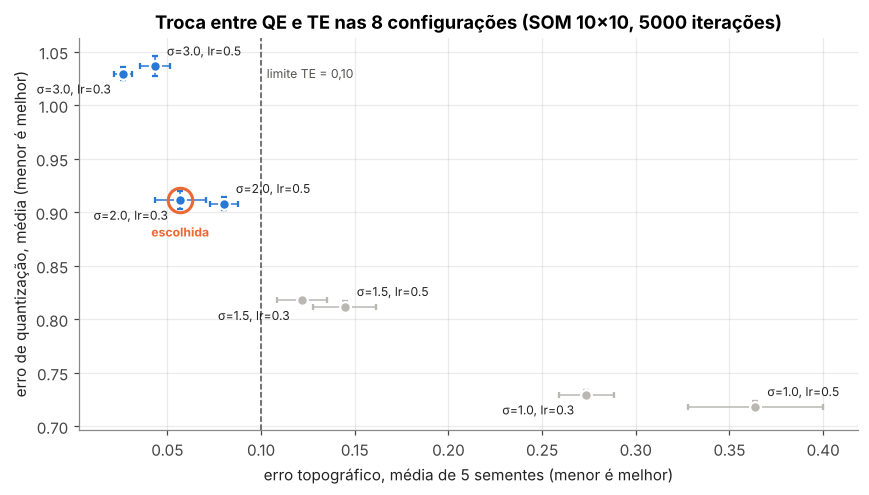

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.6))
cand = tabela["TE_media"] <= 0.10
ax.axvline(0.10, color=CINZA, ls="--", lw=1)
ax.text(0.103, tabela["QE_media"].max(), "limite TE = 0,10", color=CINZA, fontsize=8, va="top")
for _, r in tabela.iterrows():
    cor = AZUL if r["TE_media"] <= 0.10 else "#b9b8b3"
    ax.errorbar(r["TE_media"], r["QE_media"], xerr=r["TE_dp"], yerr=r["QE_dp"], fmt="o", ms=7,
                color=cor, ecolor=cor, elinewidth=1, capsize=2, mec="white", mew=1.5)
    acima = r["learning_rate"] == 0.5
    ax.annotate(f"σ={r['sigma']}, lr={r['learning_rate']}", (r["TE_media"], r["QE_media"]),
                xytext=(8, 7) if acima else (-8, -13), textcoords="offset points", fontsize=8, color="#222",
                ha="left" if acima else "right")
ax.plot(escolha["TE_media"], escolha["QE_media"], "o", ms=16, mfc="none", mec=LARANJA, mew=2)
ax.annotate("escolhida", (escolha["TE_media"], escolha["QE_media"]), xytext=(0, -24), textcoords="offset points",
            ha="center", fontsize=8, color=LARANJA, fontweight="bold")
ax.set_xlabel("erro topográfico, média de 5 sementes (menor é melhor)")
ax.set_ylabel("erro de quantização, média (menor é melhor)")
ax.set_title("Troca entre QE e TE nas 8 configurações (SOM 10×10, 5000 iterações)")
plt.tight_layout(); plt.savefig("figuras/02_grid_qe_te.png", bbox_inches="tight"); plt.show()

**Leitura:** nenhum ponto fica no canto inferior esquerdo (QE e TE baixos ao mesmo tempo). Os pontos formam uma curva:
quando um erro cai, o outro sobe. Os pontos azuis passam no limite de TE, e o círculo laranja marca a configuração escolhida.

## 6. Mais iterações ajudam?
5000 iterações sorteadas equivalem a cerca de 11 passadas pelos 440 clientes. Testamos 20.000 (cerca de 45 passadas) na configuração escolhida.

In [6]:
comp = []
for it in [5000, 20000]:
    qe, te = [], []
    for s in SEMENTES:
        m = treina(SIGMA, LR, s, it)
        qe.append(m.quantization_error(X_scaled)); te.append(m.topographic_error(X_scaled))
    comp.append({"iteracoes": it, "QE_media": np.mean(qe), "TE_media": np.mean(te)})
pd.DataFrame(comp).round(4)

,iteracoes,QE_media,TE_media
0,5000,0.9117,0.0568
1,20000,0.8872,0.0700


**Leitura:** com 4× mais iterações o QE cai só cerca de 0,025 (menos de 3%) e o TE sobe um pouco. Não compensa, então ficamos com 5000.
O mapa já convergiu.

## 7. Modelo final e entrega

In [7]:
import time
t0 = time.time()
som = treina(SIGMA, LR, SEED)
print(f"Treino em {time.time() - t0:.2f} s")
QE, TE = som.quantization_error(X_scaled), som.topographic_error(X_scaled)
print(f"QE = {QE:.4f} | TE = {TE:.4f}")

with open("dados/som.pkl", "wb") as f:
    pickle.dump(som, f)
np.save("dados/som_pesos.npy", som.get_weights())      # plano B, caso o pickle não abra em outra versão
print("Salvos: dados/som.pkl e dados/som_pesos.npy", som.get_weights().shape)

Treino em 0.18 s
QE = 0.8977 | TE = 0.0500
Salvos: dados/som.pkl e dados/som_pesos.npy (10, 10, 6)


**Leitura:** o mapa final tem **QE = 0,898** e **TE = 0,050**: só 5% dos clientes (22 de 440) têm os dois neurônios mais próximos
não vizinhos. O treino leva menos de meio segundo, sem GPU.

**Como as outras partes carregam o mapa:**
```python
with open("dados/som.pkl", "rb") as f:
    som = pickle.load(f)
```
Se der erro de versão (numpy/minisom diferentes), os pesos estão em `dados/som_pesos.npy` e os notebooks 03 a 06 já têm o plano B.

## 8. Resumo da Parte 2 (para o relatório)
- **Modelo:** SOM 10×10 (regra 5·√N ≈ 105 neurônios), inicialização por PCA, 5000 iterações, semente 42, biblioteca `minisom`.
- **Busca:** 8 configurações (`sigma` 1.0/1.5/2.0/3.0 × `learning_rate` 0.3/0.5), cada uma com 5 sementes.
- **Achado principal:** QE e TE andam em sentidos opostos. `sigma` pequeno representa bem, mas quebra a topologia (TE até 0,36).
  `sigma` grande preserva a topologia, mas representa mal (QE > 1,0).
- **Critério:** TE médio ≤ 0,10; depois, menor QE; empate (diferença menor que o desvio entre sementes) decidido pelo menor TE.
- **Escolha:** `sigma = 2.0`, `learning_rate = 0.3`, com **QE = 0,898 e TE = 0,050**.
- **Iterações:** 20.000 melhoram o QE em menos de 3%. 5000 bastam.
- **Entrega:** `dados/som.pkl` e `dados/som_pesos.npy`, além da figura `figuras/02_grid_qe_te.png`.